In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
sns.set_palette("deep")

In [3]:
metadata = pd.read_csv("sample_metadata.csv")
proteins = pd.read_csv("proteins_npx_raw.csv")
annotations = pd.read_csv("protein_annotation.csv")

In [4]:
print("Metadata:", metadata.shape)
print("Proteins:", proteins.shape)
print("Annotations:", annotations.shape)

display(metadata.head())
display(proteins.iloc[:5, :10])
display(annotations.head())

Metadata: (867, 76)
Proteins: (867, 1482)
Annotations: (1481, 12)


,sample_kit_id,subject.subjectGuid,cohort.cohortGuid,subject.biologicalSex,subject.ageGroup,sample.subjectAgeAtDraw,sample.visitName,sample.daysSinceFirstVisit,cmv_status,olink_plate_id,...,infl.rf_igm_interpretation,infl.rf_igm_result,infl.esr,lip.cholesterol_hdl,lip.cholesterol_ldl,lip.cholesterol_non_hdl,lip.cholesterol_total,lip.chlesterol_hdl_ratio,lip.triglycerides,subject_guid
0,KT00001,BR1001,BR1,Female,Young Adult,32,Flu Year 1 Day 0,0,Negative,20201752_SS200052_CARDIO_INF,...,Negative,5.902,2.0,65.0,85.0,104.0,169.0,2.6,94.0,BR1001
1,KT00002,BR1002,BR1,Male,Young Adult,28,Flu Year 1 Day 0,0,Negative,20201752_SS200050_NEURO_ONC,...,NaN,NaN,2.0,56.0,72.0,99.0,155.0,2.8,197.0,BR1002
2,KT00003,BR1003,BR1,Female,Young Adult,30,Flu Year 1 Day 0,0,Negative,20201752_SS200051_NEU_ONC,...,NaN,NaN,2.0,76.0,112.0,126.0,202.0,2.7,57.0,BR1003
3,KT00004,BR1004,BR1,Male,Young Adult,30,Flu Year 1 Day 0,0,Negative,20201752_SS200049_NEU_ONC,...,NaN,NaN,2.0,60.0,63.0,76.0,136.0,2.3,47.0,BR1004
4,KT00006,BR1005,BR1,Female,Young Adult,27,Flu Year 1 Day 0,0,Negative,20201752_SS200049_NEU_ONC,...,NaN,NaN,2.0,50.0,79.0,102.0,152.0,3.0,130.0,BR1005


,sample_kit_id,AARSD1,ABHD14B,ABL1,ACAA1,ACAN,ACE2,ACOX1,ACP5,ACP6
0,KT00001,2.3968,-0.0024,0.4328,-2.1794,0.7174,-0.5271,-0.1398,0.0383,0.0499
1,KT00002,2.5518,-0.0353,-0.1173,-0.7889,0.3991,-0.2408,0.3677,0.4900,-0.2228
2,KT00003,3.5256,0.8883,-0.2680,-1.3368,-0.1163,-0.7912,0.1919,0.1263,0.1536
3,KT00004,2.6322,0.7001,-0.1158,-0.9177,0.5898,-0.1305,0.4627,-0.0472,0.7599
4,KT00006,2.9550,-0.1049,0.0123,-0.6184,-0.0818,-0.9817,-0.5799,0.2396,-1.6798


,protein,assay,olink_id,uniprot,panel,npx_median,lod_median,n_missing,pct_below_lod,pct_missing,same_assay_as,duplicate_olink_id
0,AARSD1,AARSD1,OID21311,Q9BTE6,Oncology,2.687,-1.113,0,0.0,0.0,NaN,False
1,ABHD14B,ABHD14B,OID20921,Q96IU4,Neurology,0.776,-1.467,0,0.0,0.0,NaN,False
2,ABL1,ABL1,OID21280,P00519,Oncology,0.599,-1.636,0,0.0,0.0,NaN,False
3,ACAA1,ACAA1,OID21269,P09110,Oncology,-0.134,0.310,0,62.2,0.0,NaN,False
4,ACAN,ACAN,OID20159,P16112,Cardiometabolic,0.045,-3.888,0,0.0,0.0,NaN,False


In [5]:
# Number of unique participants
metadata["subject.subjectGuid"].nunique()

# Number of samples per participant
metadata.groupby("subject.subjectGuid").size().describe()

count    96.000000
mean      9.031250
std       2.328103
min       1.000000
25%      10.000000
50%      10.000000
75%      10.000000
max      10.000000
dtype: float64

In [6]:
data = metadata.merge(
    proteins,
    on="sample_kit_id",
    validate="one_to_one"
)

display(data[[
    "sample_kit_id",
    "subject.subjectGuid",
    "subject.ageGroup",
    "sample.visitName",
    "CXCL17"
]].head())

,sample_kit_id,subject.subjectGuid,subject.ageGroup,sample.visitName,CXCL17
0,KT00001,BR1001,Young Adult,Flu Year 1 Day 0,0.6419
1,KT00002,BR1002,Young Adult,Flu Year 1 Day 0,1.1045
2,KT00003,BR1003,Young Adult,Flu Year 1 Day 0,0.1553
3,KT00004,BR1004,Young Adult,Flu Year 1 Day 0,0.3255
4,KT00006,BR1005,Young Adult,Flu Year 1 Day 0,0.3385


In [7]:
print("Dataset shape:", data.shape)
print("Number of samples:", data.shape[0])
print("Number of columns:", data.shape[1])

print("Unique participants:",
      data["subject.subjectGuid"].nunique())

Dataset shape: (867, 1557)
Number of samples: 867
Number of columns: 1557
Unique participants: 96


In [8]:
# Check Python data types
data.dtypes.value_counts()

float64    1535
object       16
int64         6
Name: count, dtype: int64

In [9]:
# Inspect metadata variables
metadata.dtypes

sample_kit_id                object
subject.subjectGuid          object
cohort.cohortGuid            object
subject.biologicalSex        object
subject.ageGroup             object
                             ...   
lip.cholesterol_non_hdl     float64
lip.cholesterol_total       float64
lip.chlesterol_hdl_ratio    float64
lip.triglycerides           float64
subject_guid                 object
Length: 76, dtype: object

In [10]:
metadata.select_dtypes(include=["object"]).columns

Index(['sample_kit_id', 'subject.subjectGuid', 'cohort.cohortGuid',
       'subject.biologicalSex', 'subject.ageGroup', 'sample.visitName',
       'cmv_status', 'olink_plate_id', 'olink_batch_id', 'subject.race',
       'subject.ethnicity', 'sample.visitDetails',
       'cmv.igg_serology_interpretation', 'infl.rf_iga_interpretation',
       'infl.rf_igm_interpretation', 'subject_guid'],
      dtype='object')

In [11]:
metadata.select_dtypes(include=["number"]).columns

Index(['sample.subjectAgeAtDraw', 'sample.daysSinceFirstVisit',
       'n_missing_npx', 'pct_below_lod', 'subject.birthYear',
       'subject.ageAtFirstDraw', 'sample.drawYear', 'am.bmi', 'am.height',
       'am.weight', 'chem.alt', 'chem.albumin', 'chem.alkaline_phosphatase',
       'chem.ast', 'chem.t_bili', 'chem.bun', 'chem.calcium', 'chem.co2',
       'chem.cl', 'chem.creatinine', 'chem.egfr_aa', 'chem.egfr_non_aa',
       'chem.globin', 'chem.glucose', 'chem.potassium', 'chem.protein',
       'chem.sodium', 'bc.perc_basophils', 'bc.perc_eosinophils',
       'bc.perc_lymphocytes', 'bc.perc_monocytes', 'bc.perc_neutrophils',
       'bc.basophil_count', 'bc.eosinophil_count', 'bc.lymphocyte_count',
       'bc.monocyte_count', 'bc.neutrophil_count', 'bc.hematocrit',
       'bc.hemoglobin', 'bc.mch', 'bc.mchc', 'bc.mcv', 'bc.mpv',
       'bc.platelet_count', 'bc.red_blood_cell_count', 'bc.rdw', 'bc.wbc',
       'cmv.igg_serology', 'infl.anti_ccp3', 'infl.anti_ccp31', 'infl.hs_crp',
  

In [12]:
missing_summary = pd.DataFrame({
    "Missing values": data.isna().sum(),
    "Missing (%)": data.isna().mean() * 100
})

missing_summary = missing_summary[
    missing_summary["Missing values"] > 0
]

missing_summary = missing_summary.sort_values(
    "Missing (%)", ascending=False
)

display(missing_summary.head(20))

,Missing values,Missing (%)
cmv.igg_serology_interpretation,775,89.388697
cmv.igg_serology,775,89.388697
infl.anti_ccp3,770,88.811995
infl.anti_ccp31,770,88.811995
infl.rf_iga_interpretation,770,88.811995
infl.rf_iga_result,770,88.811995
infl.rf_igm_result,770,88.811995
infl.rf_igm_interpretation,770,88.811995
chem.egfr_aa,718,82.814302
chem.egfr_non_aa,717,82.698962


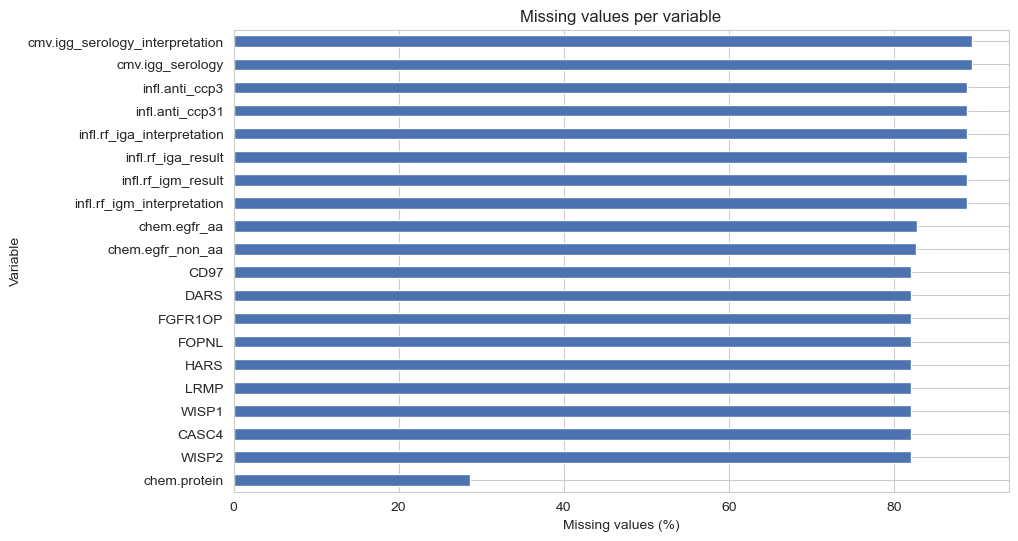

In [13]:
missing_summary.head(20)["Missing (%)"].plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Missing values (%)")
plt.ylabel("Variable")
plt.title("Missing values per variable")
plt.gca().invert_yaxis()
plt.show()

In [14]:
data.groupby("olink_batch_id")["PSG1"].apply(
    lambda x: x.isna().mean() * 100
)

olink_batch_id
20201752      0.0
20211036      0.0
20211037      0.0
20212223      0.0
Q-02017       0.0
Q-04064     100.0
Name: PSG1, dtype: float64

In [15]:
#onmogelijke waarden controleren
metadata.loc[
    metadata["am.weight"] == 0,
    ["sample_kit_id", "am.weight", "am.bmi"]
]

,sample_kit_id,am.weight,am.bmi
144,KT00348,0.0,NaN
174,KT00380,0.0,0.0
203,KT00509,0.0,NaN
238,KT00544,0.0,0.0
498,KT01975,0.0,NaN
546,KT02238,0.0,NaN


In [16]:
# Select protein measurements
protein_values = proteins.drop(columns="sample_kit_id")

# Calculate Z-scores per protein
z_scores = (
    protein_values - protein_values.mean()
) / protein_values.std()

# Count extreme values per sample
outlier_counts = (z_scores.abs() > 4).sum(axis=1)

# Create an overview
outlier_summary = pd.DataFrame({
    "sample_kit_id": proteins["sample_kit_id"],
    "n_outliers": outlier_counts
})

display(
    outlier_summary.sort_values(
        "n_outliers", ascending=False
    ).head(10)
)

,sample_kit_id,n_outliers
191,KT00397,101
662,KT02473,92
479,KT01598,48
182,KT00388,38
100,KT00280,37
846,KT03907,33
435,KT01553,32
69,KT00165,21
857,KT03919,20
71,KT00167,19


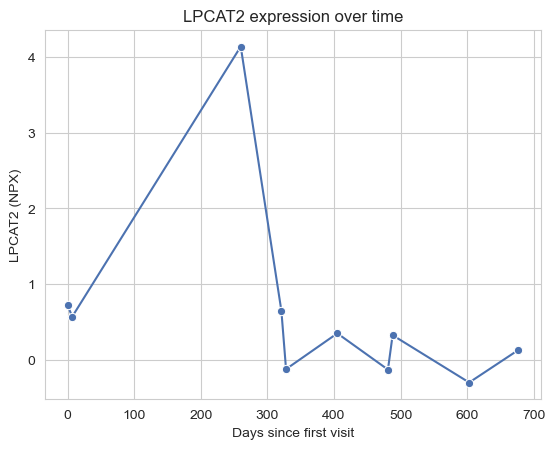

In [18]:
#komt een afwijking terug bij dezelfde persoon, LPCAT 2 is een opvallend afwijkend eiwit daarom dat we het
#hier eens visualiseren
subset = data[
    data["subject.subjectGuid"] == "BR1018"
].sort_values("sample.daysSinceFirstVisit")

sns.lineplot(
    data=subset,
    x="sample.daysSinceFirstVisit",
    y="LPCAT2",
    marker="o"
)

plt.xlabel("Days since first visit")
plt.ylabel("LPCAT2 (NPX)")
plt.title("LPCAT2 expression over time")
plt.show()